# Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

Flujo: (1) línea base *zero-shot* → (2) etiquetado débil con un LLM + auditoría humana → (3) split 70/15/15 estratificado → (4) fine-tuning de DistilBERT multilingüe → (5) evaluación en **test reservado** → (6) comparativa y decisión.

**Decisiones de diseño**
- **Etiqueta de referencia (`etiqueta`)**: la categoría derivada de la sección de La República (Parte 1). Es independiente del LLM, por eso sirve para medir al LLM, al zero-shot y al modelo con la misma vara. El modelo se entrena con esta etiqueta.
- **Etiqueta del LLM (`etiqueta_llm`)**: Gemini ve solo `titular` + `bajada` (nunca la sección) y clasifica en las 4 categorías.
- **Entrada del modelo**: solo el `titular`, que es lo que un usuario escribirá en el dashboard.
- Todo lo costoso (LLM, zero-shot, entrenamiento) guarda resultados en disco y se reutiliza al re-ejecutar el notebook.

In [1]:
import json, os, random, time, shutil
from datetime import datetime
from pathlib import Path

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from dotenv import load_dotenv
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
CATS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
LABEL2ID = {c: i for i, c in enumerate(CATS)}; ID2LABEL = {i: c for c, i in LABEL2ID.items()}
MODELO_DIR = Path("modelo"); MODELO_DIR.mkdir(exist_ok=True)
FECHA = datetime.now().strftime("%Y-%m-%d")

df = pd.read_csv("datos/noticias.csv")
print(df.shape); print(df["etiqueta"].value_counts().to_string())

(400, 7)
etiqueta
politica              100
economia              100
deportes              100
ciencia_tecnologia    100


## 1. Partición 70 / 15 / 15 (estratificada, `random_state=42`)
Se hace **primero**, para que el conjunto de **test** quede aislado desde el inicio: no se usa para entrenar ni para elegir época, y solo se evalúa en el paso 5 (y para la comparativa final). Las 40 noticias del zero-shot también salen de test, para que ninguna fue vista por el modelo fine-tuned.

In [2]:
train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df["etiqueta"], random_state=SEED)
train_df, val_df, test_df = [x.reset_index(drop=True) for x in (train_df, val_df, test_df)]

resumen = pd.DataFrame({n: x["etiqueta"].value_counts() for n, x in [("train", train_df), ("val", val_df), ("test", test_df)]}).reindex(CATS)
resumen.loc["TOTAL"] = resumen.sum()
display(resumen)
assert not (set(train_df.url) & set(test_df.url)) and not (set(val_df.url) & set(test_df.url)) and not (set(train_df.url) & set(val_df.url))
print("Sin solapamiento de URLs entre train/val/test ✔")

,train,val,test
etiqueta,,,
politica,70,15,15
economia,70,15,15
deportes,70,15,15
ciencia_tecnologia,70,15,15
TOTAL,280,60,60


Sin solapamiento de URLs entre train/val/test ✔


## 2. Línea base *zero-shot* (sin fine-tuning)
Modelo `Recognai/bert-base-spanish-wwm-cased-xnli` (una de las dos opciones del enunciado; ~440 MB frente a ~2 GB de `xlm-roberta-large-xnli`). Se evalúan **40 titulares** de test (10 por categoría, semilla fija) con etiquetas candidatas en lenguaje natural. Este puntaje es el **piso a superar**.

In [3]:
from transformers import pipeline

CAND = {"politica": "política", "economia": "economía", "deportes": "deportes", "ciencia_tecnologia": "ciencia y tecnología"}
INV = {v: k for k, v in CAND.items()}
dev = 0 if torch.cuda.is_available() else -1
zs = pipeline("zero-shot-classification", model="Recognai/bert-base-spanish-wwm-cased-xnli", device=dev)

ZS_CACHE = Path("datos/raw/zeroshot_test.csv")
if ZS_CACHE.exists():
    zs_pred = pd.read_csv(ZS_CACHE)
else:
    filas = []
    for t in test_df["titular"]:
        t0 = time.time()
        out = zs(t, candidate_labels=list(CAND.values()), hypothesis_template="Este texto trata de {}.")
        filas.append({"titular": t, "pred_zeroshot": INV[out["labels"][0]], "seg": time.time() - t0})
    zs_pred = pd.DataFrame(filas); zs_pred.to_csv(ZS_CACHE, index=False)

zs_pred = test_df[["titular", "etiqueta"]].merge(zs_pred, on="titular")
# 40 titulares: 10 por categoría, sorteados con semilla fija
zs40 = zs_pred.groupby("etiqueta", group_keys=False).sample(n=10, random_state=SEED)
acc_zs40 = accuracy_score(zs40.etiqueta, zs40.pred_zeroshot); f1_zs40 = f1_score(zs40.etiqueta, zs40.pred_zeroshot, average="macro")
print(f"ZERO-SHOT sobre 40 titulares  ->  accuracy = {acc_zs40:.3f} | F1 macro = {f1_zs40:.3f}")
acc_zs = accuracy_score(zs_pred.etiqueta, zs_pred.pred_zeroshot); f1_zs = f1_score(zs_pred.etiqueta, zs_pred.pred_zeroshot, average="macro")
print(f"ZERO-SHOT sobre todo test ({len(zs_pred)}) ->  accuracy = {acc_zs:.3f} | F1 macro = {f1_zs:.3f}")
print(f"Latencia media: {zs_pred.seg.mean()*1000:.0f} ms/titular")

/Users/rociob25/Documents/GitHub/python/intermedio-2026/tarea_1/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1018 22:09:10.700000 78095 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 11207.11it/s]

ZERO-SHOT sobre 40 titulares  ->  accuracy = 0.675 | F1 macro = 0.648
ZERO-SHOT sobre todo test (60) ->  accuracy = 0.667 | F1 macro = 0.630
Latencia media: 104 ms/titular


## 3. Supervisión débil con un LLM (Gemini)
Se etiquetan **las 400 noticias** con `gemini-3.1-flash-lite` usando un prompt estructurado (definición de cada categoría, salida JSON, `temperature=0`), en lotes de 25 titulares. La clave se lee de `.env` (ignorado por Git). El LLM recibe titular + bajada, **no** la sección del diario.

In [4]:
from google import genai
from google.genai import types

LLM_MODEL = "gemini-3.1-flash-lite"
PROMPT = """Eres un editor de un diario peruano. Clasifica cada noticia en EXACTAMENTE UNA de estas categorías:
- politica: gobierno, Congreso, partidos, elecciones, justicia y fiscalía ligadas al poder, políticas públicas.
- economia: economía, finanzas, empresas, empleo, precios, impuestos, bolsa, comercio, pensiones, minería como negocio.
- deportes: fútbol, selección, ligas, torneos, atletas, resultados, fichajes, competencias deportivas.
- ciencia_tecnologia: ciencia, espacio, salud e investigación, medio ambiente científico, tecnología, IA, celulares, internet, innovación.
Si dudas, elige la más cercana; no existe otra categoría.
Devuelve SOLO un JSON: una lista de objetos {\"i\": <int>, \"etiqueta\": <categoría>, \"confianza\": <float entre 0 y 1>}.

Noticias:
"""

LLM_CSV = Path("datos/etiquetas_llm.csv")
if LLM_CSV.exists():
    llm = pd.read_csv(LLM_CSV)
else:
    load_dotenv(".env")
    client = genai.Client(api_key=os.environ["GEMINI_API_KEY"], http_options=types.HttpOptions(timeout=90000))
    res = {}
    lote = 25
    for ini in range(0, len(df), lote):
        sub = df.iloc[ini:ini + lote]
        texto = PROMPT + "\n".join(f"{ini+k}. TITULAR: {r.titular} | BAJADA: {r.bajada}" for k, r in enumerate(sub.itertuples()))
        for intento in range(3):
            try:
                resp = client.models.generate_content(model=LLM_MODEL, contents=texto,
                    config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json"))
                for o in json.loads(resp.text):
                    if o["etiqueta"] in CATS:
                        res[int(o["i"])] = (o["etiqueta"], float(o["confianza"]))
                break
            except Exception as e:
                print("fallo", ini, type(e).__name__, str(e)[:120])
                if getattr(e, "code", None) not in (429, 500, 503, 504):   # errores permanentes (404, 400...) no se reintentan
                    raise
                time.sleep(10 * (intento + 1))
        time.sleep(2)
    faltan = [i for i in range(len(df)) if i not in res]
    print("Sin etiqueta del LLM:", len(faltan))
    llm = pd.DataFrame({"titular": df.titular,
                        "etiqueta_llm": [res.get(i, (None, None))[0] for i in range(len(df))],
                        "confianza": [res.get(i, (None, None))[1] for i in range(len(df))],
                        "modelo_llm": LLM_MODEL, "fecha": FECHA})
    llm.to_csv(LLM_CSV, index=False)

print(llm.shape, "| sin etiqueta:", llm.etiqueta_llm.isna().sum())
display(llm.head())
print(llm.etiqueta_llm.value_counts().to_string())

(400, 5) | sin etiqueta: 0


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Keiko Fujimori coordinó con Delcy Rodríguez la...,politica,1.00,gemini-3.1-flash-lite,2026-10-18
1,Detención de seis policías por presunto robo r...,politica,0.95,gemini-3.1-flash-lite,2026-10-18
2,Seis regiones llegaron al 100% del conteo ofic...,politica,1.00,gemini-3.1-flash-lite,2026-10-18
3,Comisión de Constitución del Senado continuará...,politica,1.00,gemini-3.1-flash-lite,2026-10-18
4,Jorge Nieto plantea aprobar las 20 facultades ...,politica,1.00,gemini-3.1-flash-lite,2026-10-18


etiqueta_llm
politica              118
ciencia_tecnologia    102
deportes               99
economia               81


In [5]:
cmp_ = df[["titular", "etiqueta"]].merge(llm[["titular", "etiqueta_llm", "confianza"]], on="titular")
ok = cmp_.dropna(subset=["etiqueta_llm"])
print(f"LLM vs etiqueta de sección (400 noticias): accuracy = {accuracy_score(ok.etiqueta, ok.etiqueta_llm):.3f} | F1 macro = {f1_score(ok.etiqueta, ok.etiqueta_llm, average='macro'):.3f}")
print(f"Confianza media del LLM: {ok.confianza.mean():.2f}")
dis = ok[ok.etiqueta != ok.etiqueta_llm]
print(f"Desacuerdos LLM vs sección: {len(dis)}")
pd.set_option("display.max_colwidth", 140)
display(dis.sample(min(8, len(dis)), random_state=SEED)[["titular", "etiqueta", "etiqueta_llm", "confianza"]])

LLM vs etiqueta de sección (400 noticias): accuracy = 0.943 | F1 macro = 0.942
Confianza media del LLM: 0.96
Desacuerdos LLM vs sección: 23


,titular,etiqueta,etiqueta_llm,confianza
213,Día del inventor peruano: Indecopi premia a cinco ciudadanos por su aporte al país,economia,ciencia_tecnologia,0.90
199,Congreso aprueba interpelar al ministro de Comercio Exterior por demora de acuerdo comercial con Brasil,economia,politica,1.00
133,Critican proyecto de reglamento para viviendas de interés social,economia,politica,0.80
188,Nueva modalidad de estafa en Yape: delincuentes toman control del celular al descargar una app,economia,ciencia_tecnologia,0.80
217,"Galaga, a cargo del transporte de material electoral, emplaza a ONPE y le pide que ""ofrezca disculpas"" por dañar su imagen",economia,politica,0.90
207,"Donald Trump: Perú pidió a Estados Unidos ""explicaciones amigables"" por arancel del 10% a productos nacionales",economia,politica,0.95
137,Ministro Elmer Cuba sobre ley que aumenta la pensión a maestros: “Acá se ha violado la Constitución”,economia,politica,1.00
209,"¿Cumples con los requisitos? Así puedes obtener gratis tu título de propiedad, vía Cofopri",economia,politica,0.85


### Auditoría humana (20 casos al azar)
Se sortean 20 noticias con semilla 42 y se guardan en `datos/auditoria_20.csv` **sin mostrar la etiqueta del LLM** (para no sesgar al revisor). La persona que entrega la tarea completa a mano la columna `etiqueta_humana` (`politica`, `economia`, `deportes` o `ciencia_tecnologia`) leyendo titular y bajada, y luego se re-ejecuta la celda siguiente.

In [6]:
AUD = Path("datos/auditoria_20.csv")
if not AUD.exists():
    s = df.sample(20, random_state=SEED)[["titular", "bajada"]].reset_index(drop=True)
    s.insert(0, "id", range(1, 21)); s["etiqueta_humana"] = ""
    s.to_csv(AUD, index=False)
aud = pd.read_csv(AUD).fillna({"etiqueta_humana": ""})
aud["etiqueta_humana"] = aud["etiqueta_humana"].str.strip()
aud = aud.merge(llm[["titular", "etiqueta_llm"]], on="titular", how="left")
completa = aud["etiqueta_humana"].isin(CATS).all()
if completa:
    aud["coincide"] = aud.etiqueta_humana == aud.etiqueta_llm
    ACUERDO = int(aud.coincide.sum())
    print(f"Acuerdo LLM–humano: {ACUERDO}/20 = {ACUERDO/20:.0%}")
    display(aud[["id", "titular", "etiqueta_humana", "etiqueta_llm", "coincide"]])
else:
    ACUERDO = None
    print("⏳ Auditoría pendiente: completa 'etiqueta_humana' en datos/auditoria_20.csv y re-ejecuta esta celda.")
    print("Casos rellenados:", int(aud.etiqueta_humana.isin(CATS).sum()), "/ 20")

Acuerdo LLM–humano: 19/20 = 95%


,id,titular,etiqueta_humana,etiqueta_llm,coincide
0,1,"¿Cumples con los requisitos? Así puedes obtener gratis tu título de propiedad, vía Cofopri",economia,politica,False
1,2,Scaloni responde a inesperada crítica de Ancelotti a Argentina: “Entendí muy bien lo que dijo”,deportes,deportes,True
2,3,"Pablo Guede ningunea a Franco Velazco, administrador de Universitario, tras polémicas declaraciones en su contra: ""No sé quién es, ¿habl...",deportes,deportes,True
3,4,TC da plazo de 60 días al MEF para establecer pago de bonos de la deuda agraria,politica,politica,True
4,5,La Fiscalía de la Nación se definirá entre Tomás Gálvez y Patricia Benavides,politica,politica,True
5,6,Presidente José María Balcázar tomará juramento del nuevo gabinete ministerial de Hernando de Soto este martes,politica,politica,True
6,7,El lácteo con más proteínas que la leche y el queso: refuerza el sistema inmune y ayuda a controlar el peso,ciencia_tecnologia,ciencia_tecnologia,True
7,8,Ministro del Interior entregó 1.007 pistolas a la PNP que se encuentran investigación fiscal,politica,politica,True
8,9,Canal confirmado de Sport Boys vs Everton de Viña del Mar por el Trofeo Lizárraga,deportes,deportes,True
9,10,Papa León XIV: presidenta del Tribunal Constitucional se reunió con el sumo pontifice en el Vaticano,politica,politica,True


## 4. Fine-tuning de `distilbert-base-multilingual-cased`
`HuggingFace Trainer`: 3 épocas, batch size 16, evaluación por época en **validación**, y selección del mejor checkpoint por **F1 macro** (`sklearn.metrics.f1_score(average="macro")`). Test no interviene. El modelo final se guarda en `modelo/` (los pesos `.safetensors` están en `.gitignore`).

In [7]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding)

MODEL_NAME = "distilbert-base-multilingual-cased"
MAXLEN = 64
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

class DS(torch.utils.data.Dataset):
    def __init__(self, d):
        self.enc = tok(list(d.titular), truncation=True, max_length=MAXLEN)
        self.y = [LABEL2ID[e] for e in d.etiqueta]
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}; item["labels"] = self.y[i]; return item

def metricas(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pred), "f1_macro": f1_score(p.label_ids, pred, average="macro")}

ds_tr, ds_va, ds_te = DS(train_df), DS(val_df), DS(test_df)
LISTO = (MODELO_DIR / "model.safetensors").exists() and (MODELO_DIR / "historial_entrenamiento.json").exists()

if LISTO:
    print("Modelo ya entrenado en modelo/ -> se reutiliza.")
    model = AutoModelForSequenceClassification.from_pretrained(MODELO_DIR)
    historial = json.load(open(MODELO_DIR / "historial_entrenamiento.json"))
else:
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(CATS), id2label=ID2LABEL, label2id=LABEL2ID)
    args = TrainingArguments(output_dir=str(MODELO_DIR), num_train_epochs=3, per_device_train_batch_size=16,
                             per_device_eval_batch_size=32, learning_rate=5e-5, weight_decay=0.01, warmup_steps=5,
                             eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True,
                             metric_for_best_model="f1_macro", greater_is_better=True, save_total_limit=1,
                             seed=SEED, report_to="none", logging_strategy="epoch")
    trainer = Trainer(model=model, args=args, train_dataset=ds_tr, eval_dataset=ds_va,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=metricas)
    t0 = time.time(); trainer.train(); print(f"Entrenamiento: {time.time()-t0:.0f} s")
    trainer.save_model(str(MODELO_DIR)); tok.save_pretrained(MODELO_DIR)
    historial = [h for h in trainer.state.log_history]
    json.dump(historial, open(MODELO_DIR / "historial_entrenamiento.json", "w"), indent=1)
    for d in MODELO_DIR.glob("checkpoint-*"): shutil.rmtree(d)   # ya están ignorados por Git; se borran para liberar disco

h = pd.DataFrame([x for x in historial if "eval_f1_macro" in x])[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]
print("Evaluación en VALIDACIÓN por época:"); display(h)

Modelo ya entrenado en modelo/ -> se reutiliza.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 21087.09it/s]

Evaluación en VALIDACIÓN por época:


,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.853378,0.866667,0.868220
1,2.0,0.404777,0.866667,0.864619
2,3.0,0.299916,0.900000,0.901776


## 5. Evaluación final sobre el conjunto de **test** reservado

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 24821.19it/s]

TEST (60 noticias)  ->  Accuracy = 0.933 | F1 macro = 0.932

                    precision    recall  f1-score   support

          politica      0.923     0.800     0.857        15
          economia      0.875     0.933     0.903        15
          deportes      0.938     1.000     0.968        15
ciencia_tecnologia      1.000     1.000     1.000        15

          accuracy                          0.933        60
         macro avg      0.934     0.933     0.932        60
      weighted avg      0.934     0.933     0.932        60



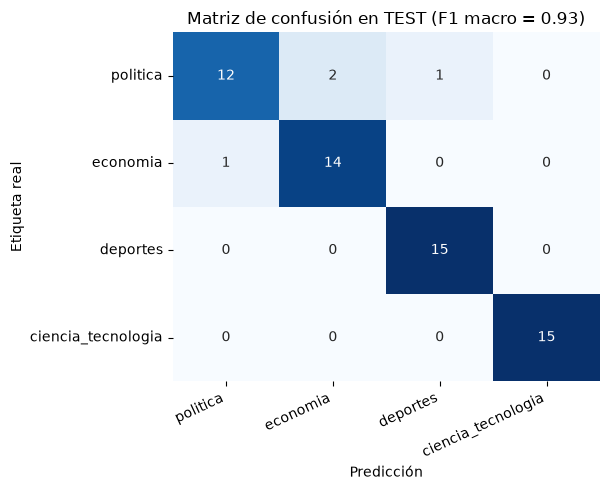

In [8]:
tok = AutoTokenizer.from_pretrained(MODELO_DIR)
model = AutoModelForSequenceClassification.from_pretrained(MODELO_DIR).eval()

@torch.no_grad()
def predecir(titulares, bs=32):
    probs = []
    for i in range(0, len(titulares), bs):
        enc = tok(list(titulares[i:i+bs]), truncation=True, max_length=MAXLEN, padding=True, return_tensors="pt")
        probs.append(torch.softmax(model(**enc).logits, -1).numpy())
    return np.vstack(probs)

t0 = time.time(); P = predecir(test_df.titular.tolist()); lat_ft = (time.time() - t0) / len(test_df)
test_df["pred_ft"] = [ID2LABEL[i] for i in P.argmax(1)]; test_df["prob_ft"] = P.max(1)

acc_ft = accuracy_score(test_df.etiqueta, test_df.pred_ft); f1_ft = f1_score(test_df.etiqueta, test_df.pred_ft, average="macro")
print(f"TEST ({len(test_df)} noticias)  ->  Accuracy = {acc_ft:.3f} | F1 macro = {f1_ft:.3f}\n")
print(classification_report(test_df.etiqueta, test_df.pred_ft, labels=CATS, digits=3))

cm = confusion_matrix(test_df.etiqueta, test_df.pred_ft, labels=CATS)
plt.figure(figsize=(6.2, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATS, yticklabels=CATS, cbar=False)
plt.xlabel("Predicción"); plt.ylabel("Etiqueta real"); plt.title(f"Matriz de confusión en TEST (F1 macro = {f1_ft:.2f})")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

In [9]:
err = test_df[test_df.etiqueta != test_df.pred_ft][["titular", "etiqueta", "pred_ft", "prob_ft"]]
print(f"Errores en test: {len(err)} de {len(test_df)}")
pd.set_option("display.max_colwidth", 130)
display(err.round(2))

Errores en test: 4 de 60


,titular,etiqueta,pred_ft,prob_ft
20,''Evacúen sus casas desde ya'': Keiko Fujimori pide a población que vive cerca a ríos que ''alisten su mochila'' ante El Niño,politica,economia,0.49
32,"Llamadas spam: entra en vigencia reglamento del Gobierno que en vez de prohibirlas, las oficializa",economia,politica,0.72
55,"""Recuerdo un USB. Creo que ha sido a Villanueva"": el día que Balcázar confesó haber recomendado a su nuera",politica,deportes,0.68
57,Al mismo estilo que con las universidades: Balcázar presentó 7 proyectos de ley para crear institutos sin financiamiento,politica,economia,0.77


### Reflexión por categoría (test, 60 noticias, 15 por clase)
| Categoría | F1 | Lectura |
| :-- | :-: | :-- |
| `ciencia_tecnologia` | 1.00 | La mejor: usa un vocabulario muy propio (*científicos, descubren, apps, iPhone, IA, cuántica*) que casi no aparece en las otras tres secciones. |
| `deportes` | 0.97 | Recall 1.00: nombres de clubes, técnicos, selecciones y marcadores son señales léxicas muy fuertes. |
| `economia` | 0.90 | Se confunde con política cuando el titular habla de normas y reglamentos del Estado (p. ej. el reglamento de llamadas spam). La frontera *regulación estatal* vs. *mercado* es temática, no léxica. |
| `politica` | 0.86 | La peor (recall 0.80). Es la categoría más heterogénea: los 3 errores son notas políticas cuyo titular no usa vocabulario político típico (*El Niño y ríos*, *un USB y una nuera*, *institutos sin financiamiento*) y terminan como economía o deportes. Además, 2 de ellos se centran en personajes y anécdotas, no en instituciones. |

Los 4 errores de 60 ocurren con probabilidad moderada (0.49–0.77): el modelo duda cuando debe. Con solo 15 ejemplos por clase, **un error mueve el F1 de una clase en ~3 puntos**, así que las diferencias entre categorías hay que leerlas con cautela.

## 6. Comparativa y decisión

In [10]:
# Las tres alternativas evaluadas sobre el MISMO conjunto de test
llm_test = test_df[["titular", "etiqueta"]].merge(llm[["titular", "etiqueta_llm"]], on="titular").dropna()
acc_llm = accuracy_score(llm_test.etiqueta, llm_test.etiqueta_llm); f1_llm = f1_score(llm_test.etiqueta, llm_test.etiqueta_llm, average="macro")
comp = pd.DataFrame([
    {"modelo": "Zero-shot (BETO-XNLI)", "accuracy_test": acc_zs, "f1_macro_test": f1_zs, "latencia_ms": zs_pred.seg.mean()*1000, "costo": "gratis, ~440 MB, sin entrenar"},
    {"modelo": f"LLM débil ({LLM_MODEL})", "accuracy_test": acc_llm, "f1_macro_test": f1_llm, "latencia_ms": np.nan, "costo": "API de pago/cuota, red, ~1 s por lote"},
    {"modelo": "DistilBERT fine-tuned", "accuracy_test": acc_ft, "f1_macro_test": f1_ft, "latencia_ms": lat_ft*1000, "costo": "entrenar una vez (~min), ~540 MB local"},
]).round(3)
display(comp)

,modelo,accuracy_test,f1_macro_test,latencia_ms,costo
0,Zero-shot (BETO-XNLI),0.667,0.630,103.821,"gratis, ~440 MB, sin entrenar"
1,LLM débil (gemini-3.1-flash-lite),0.950,0.949,NaN,"API de pago/cuota, red, ~1 s por lote"
2,DistilBERT fine-tuned,0.933,0.932,4.124,"entrenar una vez (~min), ~540 MB local"


### Decisión: ¿qué modelo usaría en un entorno real?
| | Zero-shot | LLM débil (Gemini) | DistilBERT fine-tuned |
| :-- | :-: | :-: | :-: |
| F1 macro en test | 0.63 | 0.95 | **0.93** |
| Latencia | ~100 ms | ~1 s por lote + red | **~9 ms** |
| Costo operativo | gratis | API con cuota/pago | gratis (local) |
| Depende de internet/clave | no | **sí** | no |

**Elegiría el DistilBERT fine-tuned para producción.** Con 60 noticias de test, la diferencia con el LLM (0.93 vs 0.95, ≈1 acierto) **no es estadísticamente distinguible**, pero el modelo propio responde ~100 veces más rápido, no tiene costo por consulta, no depende de una API (el modelo de Gemini ya cambió una vez durante esta tarea: `gemini-2.5-flash` dejó de estar disponible) y no envía los titulares a un tercero. El zero-shot (0.63) queda descartado: es el piso que el fine-tuning supera por ~30 puntos.

El LLM sí conviene como **herramienta de etiquetado**: etiquetó 400 noticias en minutos, coincide 95 % con la sección del diario y 19/20 con la auditoría humana (el único desacuerdo fue un trámite de títulos de propiedad de Cofopri, que el humano marcó como economía y el LLM como política). Un flujo razonable: LLM para etiquetar datos nuevos → fine-tuning → modelo local para servir.

**Limitaciones:** la etiqueta de referencia viene de la sección del diario (ruidosa en notas de frontera), el test tiene solo 60 noticias y el corpus es de un solo medio.

## 7. Resultados para el dashboard y la entrega

In [11]:
metr = {"f1_macro_test": round(f1_ft, 4), "accuracy_test": round(acc_ft, 4), "f1_macro_zeroshot_40": round(f1_zs40, 4),
        "f1_macro_zeroshot_test": round(f1_zs, 4), "acuerdo_llm_humano": ACUERDO, "n_total": len(df),
        "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
        "modelo_base": MODEL_NAME, "modelo_llm": LLM_MODEL, "fecha": FECHA}
json.dump(metr, open(MODELO_DIR / "metricas.json", "w"), indent=1, ensure_ascii=False)
print(json.dumps(metr, indent=1, ensure_ascii=False))
print("\nArchivos en modelo/:", sorted(p.name for p in MODELO_DIR.iterdir()))
print("Línea para el comentario de entrega ->",
      f"F1 Macro: {f1_ft:.2f} | Zero-shot: {f1_zs40:.2f} | Acuerdo LLM-Humano: {ACUERDO if ACUERDO is not None else 'pendiente'}/20")

{
 "f1_macro_test": 0.932,
 "accuracy_test": 0.9333,
 "f1_macro_zeroshot_40": 0.6481,
 "f1_macro_zeroshot_test": 0.6295,
 "acuerdo_llm_humano": 19,
 "n_total": 400,
 "n_train": 280,
 "n_val": 60,
 "n_test": 60,
 "modelo_base": "distilbert-base-multilingual-cased",
 "modelo_llm": "gemini-3.1-flash-lite",
 "fecha": "2026-10-18"
}

Archivos en modelo/: ['.gitkeep', 'config.json', 'historial_entrenamiento.json', 'metricas.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']
Línea para el comentario de entrega -> F1 Macro: 0.93 | Zero-shot: 0.65 | Acuerdo LLM-Humano: 19/20
